In [10]:
import torch
import torch.nn.functional as F
import pandas as pd
from puck2vec import Puck2Vec
from puck2vec_dataset import SeqDataset

In [4]:
df=pd.read_csv("data/processed_ppt.csv")


In [5]:
dataset = SeqDataset(df, n_frames=40)

In [17]:
model=Puck2Vec(n_players = dataset.n_players, player_dim=32,n_frames=40)

In [18]:
LR = 1e-4
WEIGHT_DECAY = 1e-2
BATCH_SIZE = 16
MAX_EPOCHS = 50
PATIENCE = 5          # epochs without val improvement before stopping
VAL_FRAC = 0.2
EPV_WEIGHT = 1.0      # weight of the goal (epv) loss relative to the move loss
PLAYER_DIM = 32
TRANSFORMER_DIM = 512
TRANS_LAYERS = 3
TRANS_HEADS = 8
SEED = 0
DEVICE = "cpu"

In [ ]:
import copy
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split

torch.manual_seed(SEED)
n_val = int(len(dataset) * VAL_FRAC)
train_set, val_set = random_split(dataset, [len(dataset) - n_val, n_val])
train_loader = DataLoader(train_set, batch_size=BATCH_SIZE, shuffle=True)
val_loader = DataLoader(val_set, batch_size=BATCH_SIZE)

model = Puck2Vec(n_players=dataset.n_players, player_dim=PLAYER_DIM, n_frames=dataset.n_frames,
                 transformer_dim=TRANSFORMER_DIM, trans_layers=TRANS_LAYERS, trans_heads=TRANS_HEADS).to(DEVICE)
opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

def batch_loss(batch):
    b = {k: v.to(DEVICE) for k, v in batch.items()}
    move_logits, v_logits = model(playerIds=b["player_ids"], player_pos=b["player_pos"],
                                  player_x=b["x"], player_y=b["y"], off=b["off"],
                                  player_dxs=b["dx"], player_dys=b["dy"],
                                  puck_x=b["puck_x"], puck_y=b["puck_y"])
    move_loss = F.cross_entropy(move_logits.flatten(0, 2), b["move"].flatten())
    goal = b["goal"][:, None].expand_as(v_logits[..., 0])  # one label per shot, repeated for every frame
    epv_loss = F.binary_cross_entropy_with_logits(v_logits[..., 0], goal)
    return move_loss + EPV_WEIGHT * epv_loss

history = {"train": [], "val": []}
best_val, best_state, bad_epochs = float("inf"), None, 0

for epoch in range(MAX_EPOCHS):
    model.train()
    total = 0.0
    for i, batch in enumerate(train_loader):
        loss = batch_loss(batch)
        opt.zero_grad()
        loss.backward()
        opt.step()
        total += loss.item()
        print(f"\repoch {epoch + 1} | batch {i + 1}/{len(train_loader)} | loss {loss.item():.4f}", end="")
    train_loss = total / len(train_loader)

    model.eval()
    with torch.no_grad():
        val_loss = sum(batch_loss(batch).item() for batch in val_loader) / len(val_loader)

    history["train"].append(train_loss)
    history["val"].append(val_loss)
    print(f"\repoch {epoch + 1} | train {train_loss:.4f} | val {val_loss:.4f}" + " " * 20)

    if val_loss < best_val:
        best_val, best_state, bad_epochs = val_loss, copy.deepcopy(model.state_dict()), 0
    else:
        bad_epochs += 1
        if bad_epochs >= PATIENCE:
            print(f"early stopping, val loss hasn't improved in {PATIENCE} epochs")
            break

model.load_state_dict(best_state)  # keep the best weights on held-out data
print(f"best val loss {best_val:.4f}")

epoch 1 | batch 164/416 | loss 3.6603

IndexError: argmin(): Expected reduction dim to be specified for input.numel() == 0.

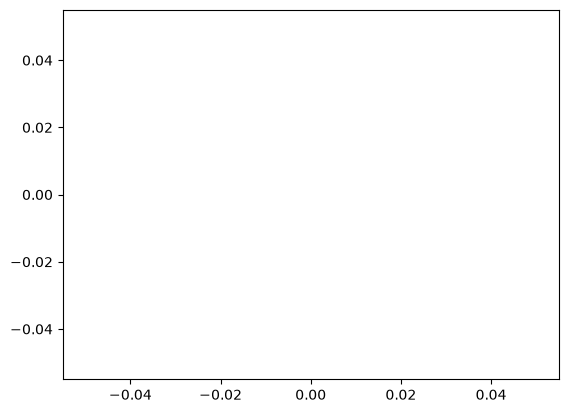

In [20]:
import matplotlib.pyplot as plt

epochs = range(1, len(history["train"]) + 1)
plt.plot(epochs, history["train"], label="train")
plt.plot(epochs, history["val"], label="val")
plt.axvline(int(torch.tensor(history["val"]).argmin()) + 1, color="gray", linestyle="--", label="best")
plt.xlabel("epoch")
plt.ylabel("loss")
plt.legend()
plt.show()

In [20]:
meta = pd.read_csv("data/metadata.csv").set_index("playerId")
idx2id = {i: pid for pid, i in dataset.player_index.items()}
torch.serialization.add_safe_globals([Puck2Vec])
state_dict = torch.load('puck2vec.pt', map_location=torch.device('cpu'), weights_only=F)
model.load_state_dict(state_dict)
W = F.normalize(model.player_embeddings.weight.detach().cpu(), dim=1)

def nearest_players(player_id, k=10):
    sims = W @ W[dataset.get_embedding_id(player_id)]
    top = sims.topk(k + 1)  # +1 since the player is their own closest match
    ids = [idx2id[int(i)] for i in top.indices]
    out = meta.reindex(ids)[["name", "position"]]
    out["similarity"] = top.values.numpy()
    return out

nearest_players(8478402)  # Connor McDavid

UnpicklingError: Weights only load failed. This file can still be loaded, to do so you have two options, [1mdo those steps only if you trust the source of the checkpoint[0m. 
	(1) In PyTorch 2.6, we changed the default value of the `weights_only` argument in `torch.load` from `False` to `True`. Re-running `torch.load` with `weights_only` set to `False` will likely succeed, but it can result in arbitrary code execution. Do it only if you got the file from a trusted source.
	(2) Alternatively, to load with `weights_only=True` please check the recommended steps in the following error message.
	WeightsUnpickler error: Unsupported global: GLOBAL torch.nn.modules.sparse.Embedding was not an allowed global by default. Please use `torch.serialization.add_safe_globals([torch.nn.modules.sparse.Embedding])` or the `torch.serialization.safe_globals([torch.nn.modules.sparse.Embedding])` context manager to allowlist this global if you trust this class/function.

Check the documentation of torch.lo

In [ ]:


emb = model.player_embeddings.weight.detach().cpu().numpy()
emb_df = pd.DataFrame(emb, columns=[f"e{i}" for i in range(emb.shape[1])])
emb_df.insert(0, "pid", [idx2id[i] for i in range(len(emb_df))])
emb_df.insert(1, "name", meta["name"].reindex(emb_df["pid"]).values)
emb_df.insert(2, "pos", meta["position"].reindex(emb_df["pid"]).values)
emb_df

,pid,name,pos,e0,e1,e2,e3,e4,e5,e6,...,e22,e23,e24,e25,e26,e27,e28,e29,e30,e31
0,8470594,NaN,NaN,0.056186,-1.171574,0.992204,-0.389845,-0.805805,-0.578131,0.620699,...,-0.301866,-0.556284,-0.223478,-1.444081,0.048700,1.222353,-1.376296,-1.443356,-1.444005,-1.743611
1,8470600,Ryan Suter,D,-0.138878,-0.808699,-0.440696,0.737760,-0.998559,2.122302,-0.656667,...,0.163029,-1.293889,0.731950,1.807448,-0.246934,2.466531,0.621175,0.058821,1.155918,-0.360828
2,8470604,Jeff Carter,C,-1.712233,-0.387825,-0.125104,0.956643,1.031518,0.422898,-1.128916,...,-1.039284,-0.416067,0.826691,0.620114,-1.034232,-0.352067,0.087671,0.488463,0.292491,-0.724271
3,8470610,Zach Parise,L,-1.759897,-1.923800,0.585166,-1.687349,0.727111,-0.441628,0.350649,...,-0.128885,2.446169,-1.435307,0.756595,-0.347108,-0.227098,0.526582,0.415614,0.273630,0.237294
4,8470613,Brent Burns,D,2.066330,0.258407,-0.120146,-1.616726,1.923100,-0.148443,-1.839175,...,-0.433041,-0.412665,-0.785442,-0.841378,0.263367,0.453924,0.527687,-2.565454,0.543102,-1.147062
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1242,8485512,Tim Washe,C,-0.349535,0.233298,-1.551206,1.781468,0.781167,-0.322503,0.087940,...,1.250592,-0.229403,-1.059190,0.700180,0.900494,-0.008200,0.239802,-0.086906,-0.728414,1.230818
1243,8485702,Max Shabanov,R,-0.562080,-0.626568,-0.801117,-0.801699,-0.181596,0.338782,0.600791,...,-1.219849,-1.668385,0.745480,-0.127753,0.275917,1.969923,0.089173,-1.146212,0.526905,-1.725990
1244,8486056,Tyson Gross,C,-0.114476,0.311103,0.664822,-0.781290,-0.375300,-0.063177,-0.324118,...,-1.481967,0.177841,-0.898772,-0.540557,-0.038182,0.734450,-0.376227,-0.545678,-1.384709,-0.176865
1245,8486166,Viking Gustafsson Nyberg,D,0.475589,0.249706,1.578475,1.185044,0.362369,-0.178401,0.500132,...,-0.612977,-0.011685,-0.082537,0.312934,-0.175960,-0.257011,-0.800887,-0.689350,-0.779892,-0.212733


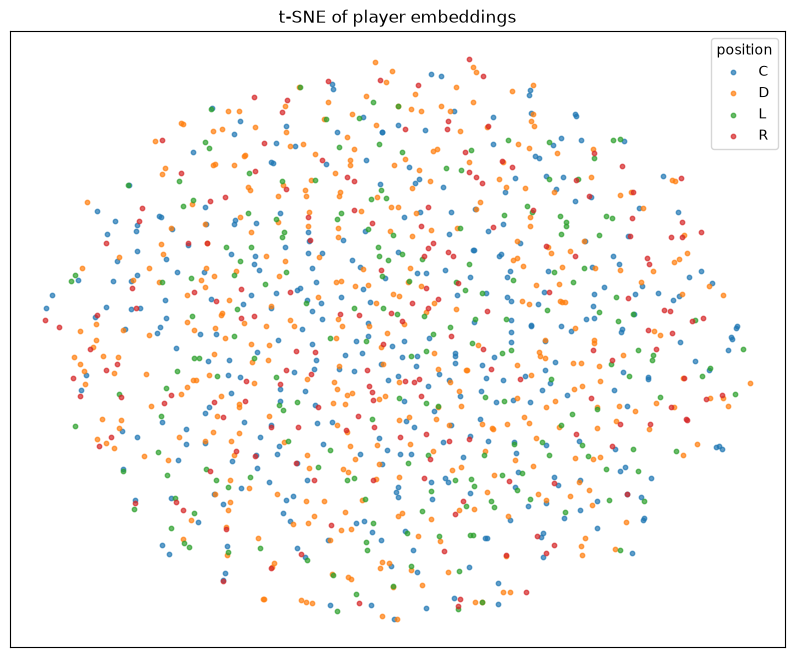

In [44]:
from sklearn.manifold import TSNE

xy = TSNE(n_components=2, perplexity=30, metric="cosine", random_state=SEED).fit_transform(emb_df.filter(regex=r"^e\d+$").values)
emb_df["tsne_x"], emb_df["tsne_y"] = xy[:, 0], xy[:, 1]

fig, ax = plt.subplots(figsize=(10, 8))
for pos, g in emb_df.groupby("pos"):
    ax.scatter(g["tsne_x"], g["tsne_y"], s=10, alpha=0.7, label=pos)

ax.set_title("t-SNE of player embeddings")
ax.legend(title="position")
ax.set_xticks([])
ax.set_yticks([])
plt.show()

In [1]:
emb_df

NameError: name 'emb_df' is not defined